In [2]:
import sys
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent                 # notebook 在 notebooks/，專案根目錄是上一層
sys.path.insert(0, str(ROOT / 'lib'))    # 讓 import tick_plot / minute_profile ... 找得到

folder = ROOT / 'data' / '20261017高點研究'
df_dict = pd.read_pickle(folder / 'df_dict_ticks.pkl.gz', compression='gzip')
print(type(df_dict), len(df_dict))

<class 'dict'> 290


In [3]:
# 290 個區間，各自一個 df，放進 list：df_list[i]
df_list = list(df_dict.values())

# 對應的區間 (start, end)：key_list[i] 就是 df_list[i] 的區間
key_list = list(df_dict.keys())

print(len(df_list))
df_list[0].head()

290


,ts,close,bid_price,ask_price,volume,bid_volume,ask_volume,tick_type
21750409,2021-05-13 08:49:00.288,15643.0,15643.0,15645.0,1,2,8,2
21750410,2021-05-13 08:49:00.370,15644.0,15643.0,15644.0,1,2,1,1
21750411,2021-05-13 08:49:00.399,15645.0,15643.0,15644.0,7,2,1,1
21750412,2021-05-13 08:49:00.463,15645.0,15643.0,15644.0,1,2,1,1
21750413,2021-05-13 08:49:00.498,15646.0,15643.0,15644.0,1,2,1,1


In [17]:
df_list[0][36000:]

,ts,close,bid_price,ask_price,volume,bid_volume,ask_volume,tick_type
21786409,2021-05-13 09:44:32.173,15882.0,15881.0,15886.0,4,3,4,2
21786410,2021-05-13 09:44:32.232,15880.0,15881.0,15886.0,1,3,4,2
21786411,2021-05-13 09:44:32.260,15884.0,15881.0,15886.0,1,3,4,1
21786412,2021-05-13 09:44:32.489,15883.0,15880.0,15884.0,1,4,6,2
21786413,2021-05-13 09:44:32.590,15884.0,15880.0,15884.0,2,4,6,1
...,...,...,...,...,...,...,...,...
21795672,2021-05-13 09:59:58.214,15728.0,15724.0,15728.0,1,2,5,1
21795673,2021-05-13 09:59:58.825,15727.0,15724.0,15727.0,1,1,2,1
21795674,2021-05-13 09:59:59.377,15728.0,15724.0,15727.0,1,1,3,1
21795675,2021-05-13 09:59:59.635,15728.0,15725.0,15728.0,1,1,4,1


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


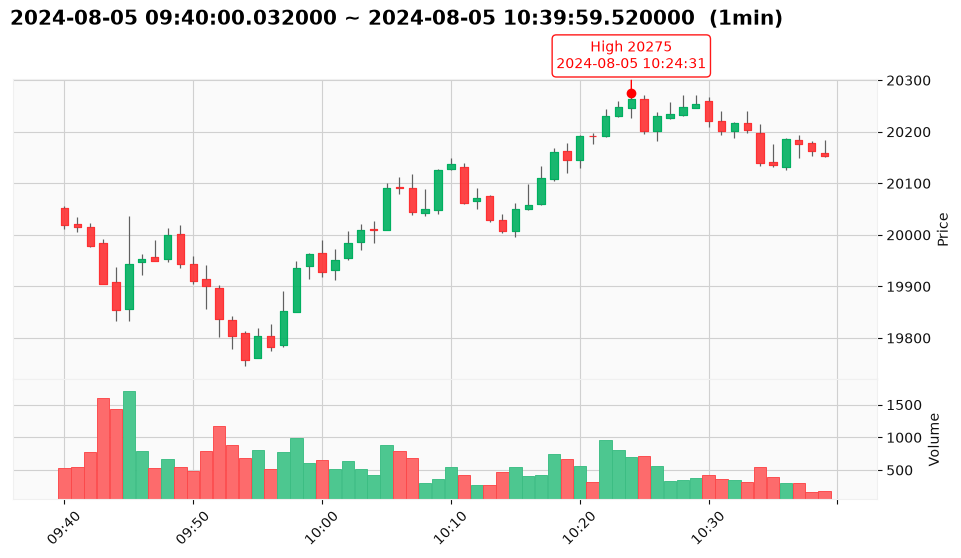

In [5]:
from tick_plot import plot_tick_frame

fig, axes, price = plot_tick_frame(df_list[1])                          # 預設不標記
# plot_tick_frame(df_list[0], mark_time='2021-05-13 09:30')             # 要標的話指定時間

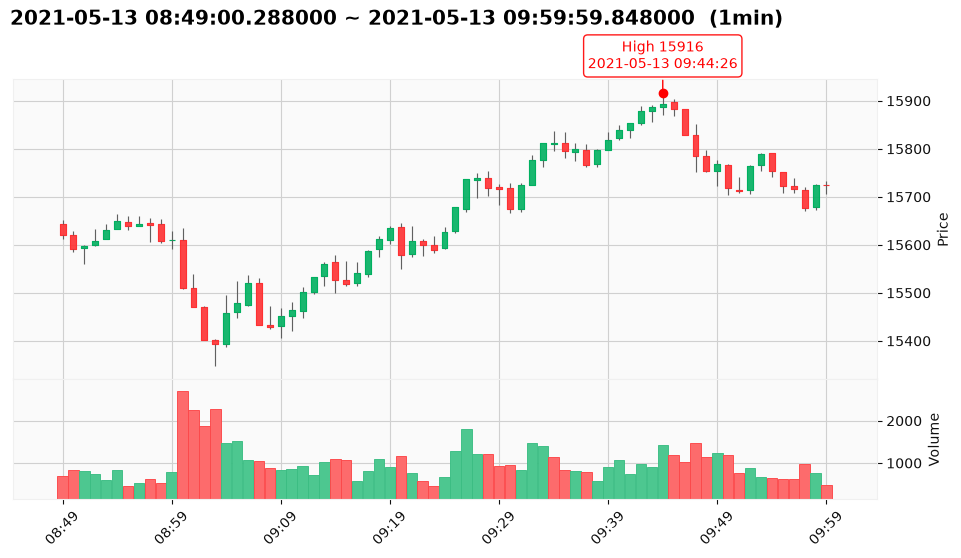

In [ ]:
fig, axes, price = plot_tick_frame(df_list[0]) 

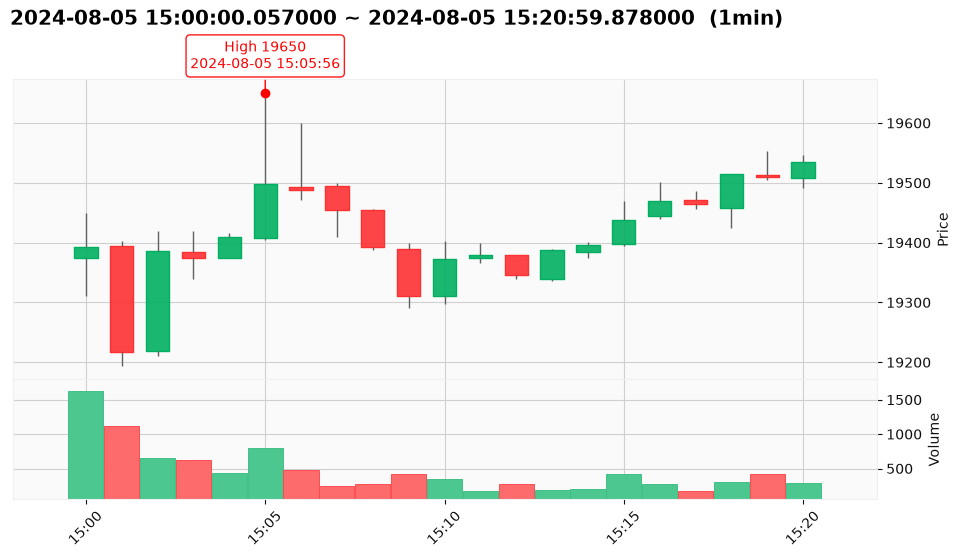

In [ ]:
fig, axes, price = plot_tick_frame(df_list[2])

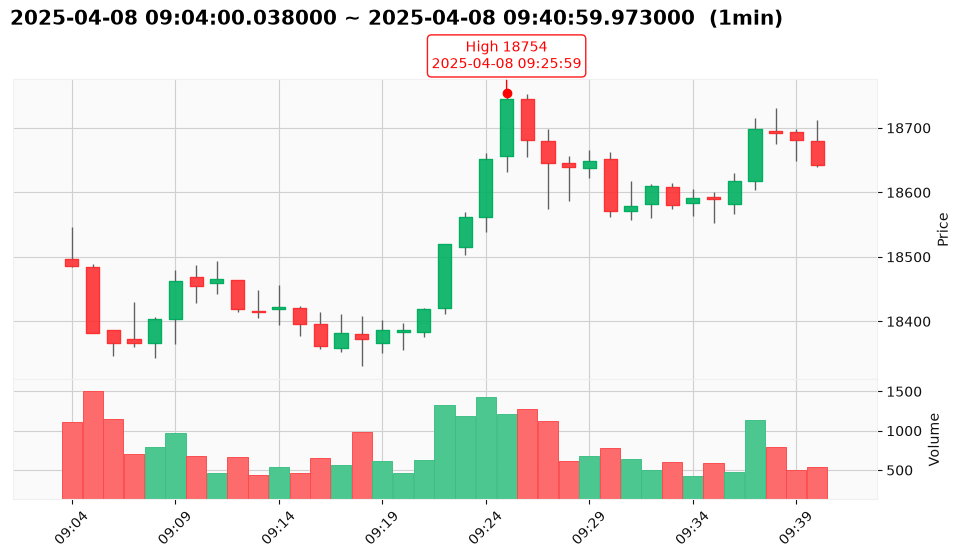

In [9]:
fig, axes, price = plot_tick_frame(df_list[5]) 

In [ ]:
from minute_profile import minute_profile, save_minute_profile

# 每分鐘各價位的成交量分布，並存到 analysis/2026-10-17_每分K統計/
prof, path = save_minute_profile(df_list[0], 'df_0', out_dir=ROOT / 'analysis' / '2026-10-17_每分K統計')
print(path)
prof.head(10)

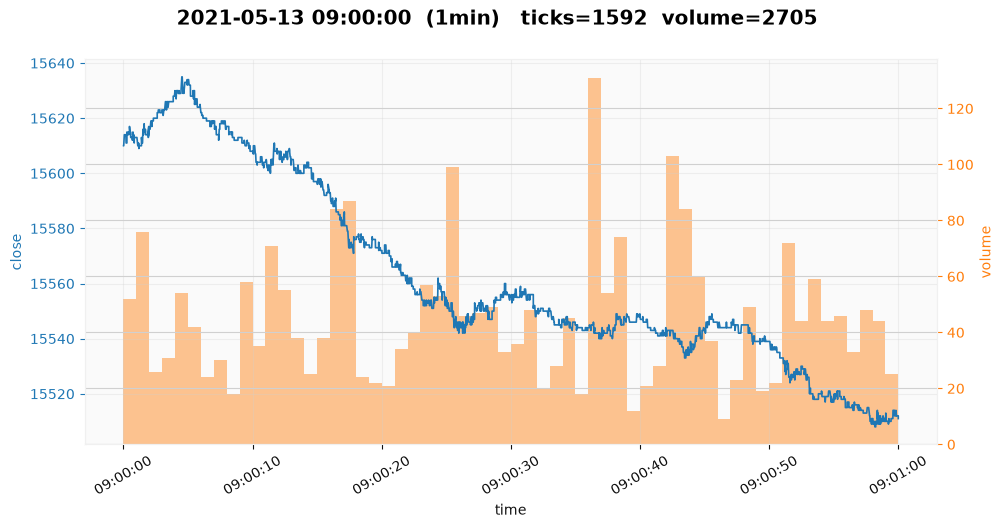

In [5]:
import importlib, minute_profile
importlib.reload(minute_profile)   # 改過 .py 後重新載入
from minute_profile import plot_minute_distribution, plot_minute_overlay

# 一張圖疊加：左 Y 軸 close 折線、右 Y 軸 volume 長條（每 1 秒）
fig, axes = plot_minute_overlay(df_list[0], minute='2021-05-13 09:00', bin='1s')

# 原本的「左折線＋右價位 histogram」版本
# fig, axes = plot_minute_distribution(df_list[0], minute='2021-05-13 09:00')

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

df0 = df_list[0]
out_dir = ROOT / 'analysis' / '2026-10-17_每分K統計' / 'df_0_plots'
out_dir.mkdir(parents=True, exist_ok=True)

# df 0 的每一分鐘各畫一張（顯示並存檔）
for m in pd.to_datetime(df0['ts']).dt.floor('1min').unique():
    fig, _ = plot_minute_overlay(df0, m, bin='1s')
    fig.savefig(out_dir / f'{m:%Y%m%d_%H%M}.png', dpi=80)
    plt.show()
    plt.close(fig)

In [6]:
importlib.reload(minute_profile)
from minute_profile import save_minute_stats

# 每分 K 的 price / volume 統計 (mean/median/max/min)，存到 analysis/2026-10-17_每分K統計/
stats, path = save_minute_stats(df_list[0], 'df_0', out_dir=ROOT / 'analysis' / '2026-10-17_每分K統計')
print(path)
stats.head()

minute_profile\df_0_stats.csv


,close_count,close_mean,close_std,close_min,close_q01,close_q05,close_q10,close_q25,close_q50,close_q75,...,volume_q75,volume_q90,volume_q95,volume_q99,volume_max,volume_range,volume_iqr,volume_skew,volume_kurt,volume_sum
minute,,,,,,,,,,,,,,,,,,,,,
2021-05-13 08:49:00,403,15638.218362,11.292227,15613.0,15616.00,15618.0,15619.0,15627.0,15644.0,15646.0,...,2.0,3.0,4.00,9.98,32,31,1.0,7.799558,81.463306,694
2021-05-13 08:50:00,507,15602.698225,10.468551,15586.0,15587.00,15589.3,15592.0,15594.0,15601.0,15606.5,...,1.0,2.0,4.00,12.88,30,29,0.0,7.568407,73.191392,832
2021-05-13 08:51:00,496,15583.322581,9.459151,15561.0,15562.95,15565.0,15569.0,15577.0,15585.0,15592.0,...,2.0,3.0,4.00,8.00,35,34,1.0,9.976950,141.512833,822
2021-05-13 08:52:00,406,15618.490148,8.838393,15598.0,15599.00,15600.0,15603.0,15613.0,15621.0,15625.0,...,2.0,3.0,4.75,11.00,28,27,1.0,6.486590,56.411729,740
2021-05-13 08:53:00,320,15632.300000,6.931641,15612.0,15615.00,15618.0,15622.0,15627.0,15634.0,15637.0,...,2.0,3.1,5.00,9.81,19,18,1.0,4.470243,28.274339,596


In [19]:
from tick_utils import slice_ticks

# 看某一段時間的 tick 內容（前後都含）
df_slice = slice_ticks(df_list[0], '2021-05-13 09:44:00', '2021-05-13 09:45:00')
print(len(df_slice))
df_slice

806


,ts,close,bid_price,ask_price,volume,bid_volume,ask_volume,tick_type
21785939,2021-05-13 09:44:00.028,15888.0,15885.0,15889.0,1,2,3,1
21785940,2021-05-13 09:44:00.288,15887.0,15885.0,15889.0,1,2,3,2
21785941,2021-05-13 09:44:00.402,15889.0,15886.0,15889.0,1,2,4,1
21785942,2021-05-13 09:44:00.407,15889.0,15886.0,15889.0,1,2,4,1
21785943,2021-05-13 09:44:00.416,15889.0,15886.0,15889.0,1,2,4,1
...,...,...,...,...,...,...,...,...
21786740,2021-05-13 09:44:59.632,15893.0,15895.0,15896.0,3,1,1,2
21786741,2021-05-13 09:44:59.666,15893.0,15895.0,15896.0,1,1,1,2
21786742,2021-05-13 09:44:59.683,15892.0,15895.0,15896.0,1,1,1,2
21786743,2021-05-13 09:44:59.692,15893.0,15895.0,15896.0,1,1,1,2


In [23]:
from minute_profile import save_minute_summary

# 每分鐘：開高低收、總成交量、type1(外盤)/type2(內盤) 的筆數與成交量
# 先看 df 0, df 1，各存一個 csv 到 analysis/2026-10-17_每分K統計/
for i in [0, 1]:
    summary, path = save_minute_summary(df_list[i], f'df_{i}', out_dir=ROOT / 'analysis' / '2026-10-17_每分K統計')
    print(f'df {i}:', path, summary.shape)
    display(summary)

df 0: minute_profile\df_0_summary.csv (71, 9)


,open,high,low,close,volume,type1_count,type1_volume,type2_count,type2_volume
minute,,,,,,,,,
2021-05-13 08:49:00,15643.0,15652.0,15613.0,15620.0,694,163,328,223,346
2021-05-13 08:50:00,15620.0,15629.0,15586.0,15591.0,832,209,345,289,471
2021-05-13 08:51:00,15593.0,15599.0,15561.0,15597.0,822,218,351,260,449
2021-05-13 08:52:00,15599.0,15633.0,15598.0,15608.0,740,207,359,184,361
2021-05-13 08:53:00,15612.0,15644.0,15612.0,15631.0,596,158,296,155,291
...,...,...,...,...,...,...,...,...,...
2021-05-13 09:55:00,15752.0,15752.0,15707.0,15723.0,616,171,261,238,343
2021-05-13 09:56:00,15722.0,15739.0,15707.0,15716.0,611,177,295,204,302
2021-05-13 09:57:00,15714.0,15721.0,15670.0,15677.0,987,227,338,368,622


df 1: minute_profile\df_1_summary.csv (60, 9)


,open,high,low,close,volume,type1_count,type1_volume,type2_count,type2_volume
minute,,,,,,,,,
2024-08-05 09:40:00,20052.0,20056.0,20012.0,20019.0,526,155,194,192,302
2024-08-05 09:41:00,20022.0,20034.0,20005.0,20015.0,546,177,267,177,261
2024-08-05 09:42:00,20016.0,20024.0,19976.0,19978.0,777,151,224,229,513
2024-08-05 09:43:00,19984.0,19992.0,19904.0,19904.0,1600,394,517,562,1024
2024-08-05 09:44:00,19908.0,19937.0,19832.0,19854.0,1430,359,572,435,832
2024-08-05 09:45:00,19857.0,20037.0,19833.0,19943.0,1715,603,907,542,739
2024-08-05 09:46:00,19947.0,19963.0,19922.0,19954.0,798,278,466,211,302
2024-08-05 09:47:00,19957.0,19990.0,19950.0,19950.0,535,157,273,166,248
2024-08-05 09:48:00,19953.0,20013.0,19947.0,19999.0,663,248,417,154,224


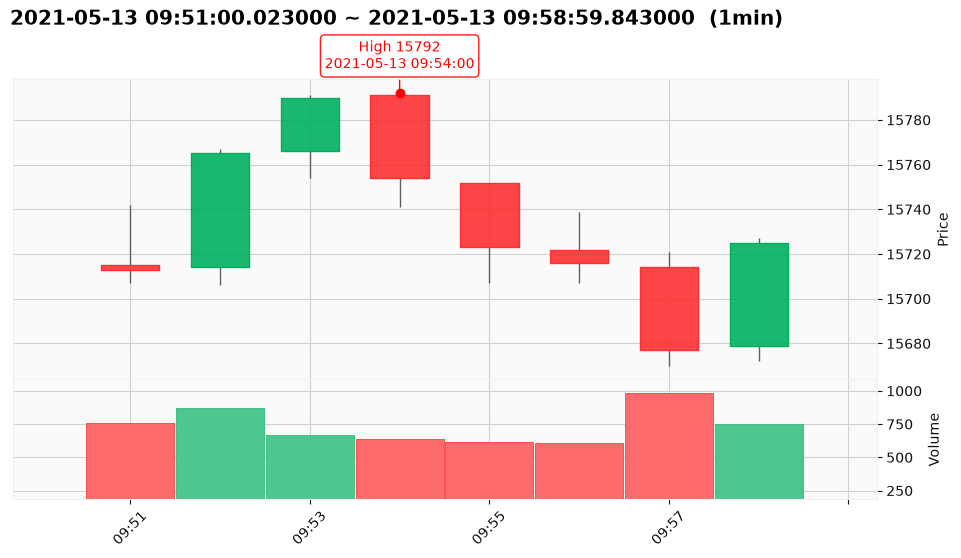

In [31]:
import tick_plot
importlib.reload(tick_plot)
from tick_plot import plot_tick_frame

# 只畫某一段時間（只給時間時，日期取 df 第一筆 tick 的日期）
fig, axes, _ = plot_tick_frame(df_list[0], freq='1min', start='09:51', end='09:59')

minute_profile\df_0_type1_segments.csv


,start,end,mark,n_slots,closed,start_ratio,mark_ratio
0,2021-05-13 08:49:00,2021-05-13 08:51:00,NaT,3,True,0.472622,NaN
1,2021-05-13 08:52:00,2021-05-13 08:59:00,2021-05-13 08:54:00,8,True,0.485135,0.583836
2,2021-05-13 09:04:00,2021-05-13 09:29:00,2021-05-13 09:26:00,26,True,0.530681,0.594699
3,2021-05-13 09:31:00,2021-05-13 09:47:00,2021-05-13 09:44:00,17,True,0.530249,0.523013
4,2021-05-13 09:48:00,2021-05-13 09:55:00,2021-05-13 09:53:00,8,True,0.490334,0.547904
5,2021-05-13 09:56:00,2021-05-13 09:59:00,2021-05-13 09:59:00,4,False,0.482815,0.534021


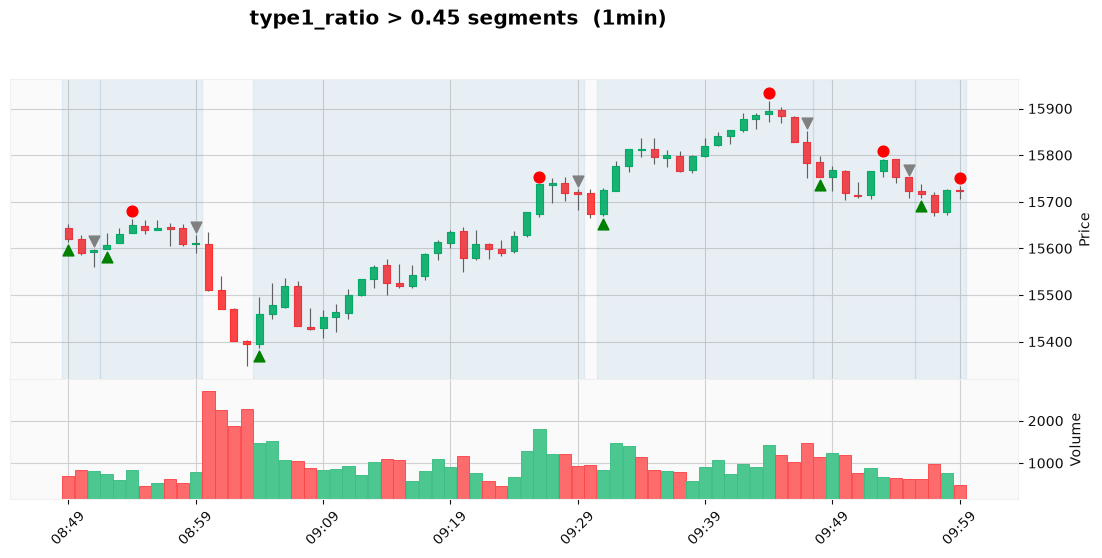

In [33]:
import minute_profile, type1_segments
importlib.reload(minute_profile)      # 先重載被依賴的模組
importlib.reload(type1_segments)
from type1_segments import plot_type1_segments, save_type1_segments

# 1 分 K：type1_ratio > 0.45 起算，連續兩根 < 0.45 結束；標出區間內最後一次 ratio > 0.5 的點
fig, axes, segments = plot_type1_segments(df_list[0], threshold=0.45, mark_threshold=0.5)
segments, path = save_type1_segments(df_list[0], 'df_0', out_dir=ROOT / 'analysis' / '2026-10-18_type1區間與最高點')   # 存 analysis/2026-10-18_type1區間與最高點/
print(path)
segments

In [35]:
import minute_profile, type1_segments
importlib.reload(minute_profile)
importlib.reload(type1_segments)
from type1_segments import type1_segments_all

# 所有 df 都跑一次，並檢查標記點是否剛好落在「區間最高價」那根 K 棒
all_seg = type1_segments_all(df_list, key_list)
all_seg.to_csv(ROOT / 'analysis' / '2026-10-18_type1區間與最高點' / 'all_type1_segments.csv', index=False)

marked = all_seg[all_seg['mark'].notna()]
hit = marked[marked['mark_is_max']]
hit.to_csv(ROOT / 'analysis' / '2026-10-18_type1區間與最高點' / 'all_type1_segments_mark_is_max.csv', index=False)
print(f'有標記點的區間 {len(marked)} 個，與區間最高價重疊 {len(hit)} 個，涵蓋 {hit["df_idx"].nunique()} 個 frames')
sorted(hit['df_idx'].unique())   # 有重疊的 frame 編號

有標記點的區間 1828 個，與區間最高價重疊 852 個，涵蓋 267 個 frames


[np.int64(0),
 np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(10),
 np.int64(11),
 np.int64(12),
 np.int64(13),
 np.int64(14),
 np.int64(15),
 np.int64(16),
 np.int64(17),
 np.int64(18),
 np.int64(19),
 np.int64(20),
 np.int64(21),
 np.int64(22),
 np.int64(23),
 np.int64(24),
 np.int64(25),
 np.int64(26),
 np.int64(27),
 np.int64(28),
 np.int64(29),
 np.int64(30),
 np.int64(31),
 np.int64(32),
 np.int64(33),
 np.int64(34),
 np.int64(35),
 np.int64(37),
 np.int64(38),
 np.int64(39),
 np.int64(40),
 np.int64(41),
 np.int64(44),
 np.int64(45),
 np.int64(46),
 np.int64(47),
 np.int64(48),
 np.int64(49),
 np.int64(50),
 np.int64(51),
 np.int64(52),
 np.int64(53),
 np.int64(54),
 np.int64(55),
 np.int64(56),
 np.int64(57),
 np.int64(58),
 np.int64(59),
 np.int64(60),
 np.int64(61),
 np.int64(62),
 np.int64(63),
 np.int64(66),
 np.int64(67),
 np.int64(68),
 np.int64(71),
 np.int64(72),
 np.int64(73),
 np.int64(74),
 np.

In [ ]:
from type1_segments import frame_max_vs_marks

# 每個 df：整個 df 的最高點那一分鐘，有沒有剛好被 ★ 標到（時間完全相同才算）
per_frame, _ = frame_max_vs_marks(df_list, key_list)
per_frame.to_csv(ROOT / 'analysis' / '2026-10-18_type1區間與最高點' / 'frame_max_vs_mark.csv', index=False)

print(f'{per_frame["hit"].sum()} / {len(per_frame)} 個 df 中獎')
per_frame[per_frame['hit']]

In [ ]:
import backtest_report
importlib.reload(backtest_report)
from backtest_report import run_report

# 讀 marks/type1/ 的 CSV，報告輸出到 reports/type1/index.html（先跑 python strategies/type1.py 產生 CSV）
report_path, result = run_report(ROOT / 'marks' / 'type1', df_list=df_list, key_list=key_list)